# Exploring the study habits survey

A step-by-step walkthrough of the same analysis that `python -m study_habits` runs, so you can see each pandas step and its output.

> The data is **simulated** (see `src/study_habits/simulate.py`). The relationships were chosen on purpose, so the point here is practising the workflow, not making claims about real students.

In [1]:
import sys

sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import pandas as pd

from study_habits import analysis
from study_habits.clean import clean

pd.set_option('display.width', 120)

## 1. Load the raw export

If `data/survey_raw.csv` doesn't exist yet, run `python -m study_habits` from the project root first.

In [2]:
raw = pd.read_csv('../data/survey_raw.csv')
print(raw.shape)
raw.head(8)

(408, 10)


,student_id,major,year,part_time_job,sleep_hours,study_hours_week,social_media_hours_day,coffee_cups_day,attendance_pct,exam_score
0,S1220,biology,1,TRUE,6.3,5.2,1.3,2,77.0,62.2
1,S1295,Business,2,No,7.3,12.7,4.9,2,62.0,61.7
2,S1391,Biology,1,No,7.3,9.0,3.7,0,84.0,66.0
3,S1357,Bio,1,No,7.1,14.8,1.6,2,83.0,69.9
4,S1384,Biology,2,TRUE,6.4,6.9,5.1,1,68.0,52.4
5,S1228,Business,3,No,5.2,9.8,4.3,2,72.0,61.6
6,S1284,Arts,1,TRUE,5.0,17.2,2.7,3,97.0,70.8
7,S1308,biology,1,No,5.8h,3.1,5.7,2,73.0,34.8


Straight away there are problems: majors typed in different ways, units inside number columns, and `NaN`s.

In [3]:
raw['major'].value_counts().head(12)

major
Computer Science    68
Business            60
Biology             59
Engineering         49
Arts                37
Business            15
BIOLOGY             15
Bus.                11
computer science    11
biology             10
arts                 9
business             9
Name: count, dtype: int64

In [4]:
raw.dtypes

student_id                    str
major                         str
year                        int64
part_time_job                 str
sleep_hours                   str
study_hours_week          float64
social_media_hours_day    float64
coffee_cups_day               str
attendance_pct            float64
exam_score                float64
dtype: object

In [5]:
raw.isna().sum()

student_id                 0
major                      0
year                       0
part_time_job              0
sleep_hours               11
study_hours_week           0
social_media_hours_day    12
coffee_cups_day            0
attendance_pct            12
exam_score                 0
dtype: int64

## 2. Clean it

`clean()` drops duplicates, standardises majors and yes/no answers, strips units like `'2 cups'`, turns impossible values (like 75 hours of sleep) into missing values, and fills gaps with the median for that student's major.

In [6]:
df, log = clean(raw)
pd.DataFrame(log.steps, columns=['step', 'count'])

,step,count
0,rows in raw export,408
1,exact duplicate rows removed,8
2,repeat submissions (same student_id) removed,0
3,major spellings standardised,133
4,yes/no answers standardised,395
5,sleep_hours: units/text stripped,15
6,coffee_cups_day: units/text stripped,25
7,sleep_hours: impossible values set to missing,4
8,attendance_pct: impossible values set to missing,3
9,missing numeric values (filled with the major'...,42


In [7]:
df.dtypes

student_id                     str
major                     category
year                         int64
part_time_job              boolean
sleep_hours                float64
study_hours_week           float64
social_media_hours_day     float64
coffee_cups_day              int64
attendance_pct             float64
exam_score                 float64
dtype: object

In [8]:
analysis.summary(df)

,mean,std,min,50%,max
study_hours_week,12.3,6.3,2.1,10.8,40.0
sleep_hours,6.6,1.1,3.5,6.6,10.0
social_media_hours_day,2.8,1.3,0.2,2.8,6.9
coffee_cups_day,2.0,1.4,0.0,2.0,7.0
attendance_pct,82.9,10.9,43.0,83.0,100.0
exam_score,65.2,10.7,27.5,65.2,89.2


## 3. What correlates with exam score?

In [9]:
analysis.correlations(df)['exam_score'].drop('exam_score').sort_values()

social_media_hours_day   -0.26
coffee_cups_day          -0.03
attendance_pct            0.26
sleep_hours               0.37
study_hours_week          0.62
Name: exam_score, dtype: float64

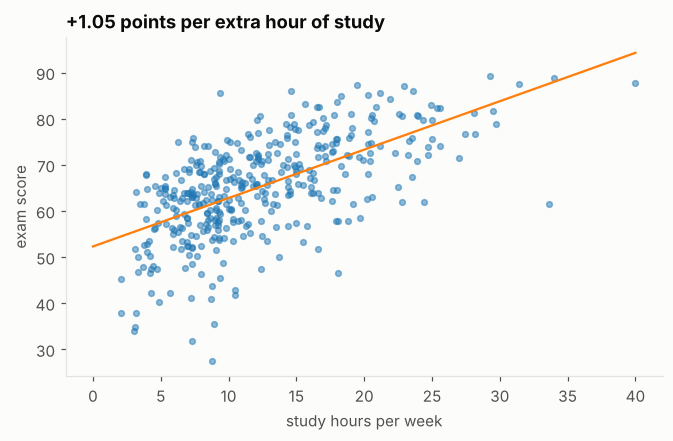

In [10]:
import numpy as np

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df['study_hours_week'], df['exam_score'], s=14, alpha=0.5)
slope, intercept = np.polyfit(df['study_hours_week'], df['exam_score'], 1)
xs = np.linspace(0, df['study_hours_week'].max(), 50)
ax.plot(xs, slope * xs + intercept, color='tab:orange')
ax.set_xlabel('study hours per week')
ax.set_ylabel('exam score')
ax.set_title(f'+{slope:.2f} points per extra hour of study');

## 4. Sleep: is more always better?

In [11]:
analysis.score_by_sleep(df)

,mean,count
sleep_hours,,
<5,47.6,26
5-6,63.3,82
6-7,65.9,142
7-8,69.1,104
8-9,67.9,39
9+,65.4,7


Scores climb up to 7-8 hours and then level off. A straight line (correlation) can't show that shape, which is why grouping with `pd.cut` is useful.

## 5. Coffee

In [12]:
analysis.score_by_coffee(df)

,mean,sem,count
coffee_cups_day,,,
0,62.63,1.48,54
1,65.92,1.02,115
2,66.19,1.10,94
3,66.85,1.24,77
4,63.35,1.43,41
5+,60.43,2.26,19


Coffee's correlation with score is about zero, yet the grouped table shows a clear upside-down U. Two opposite effects cancel out in a single correlation number. Lesson: always plot the data.

## 6. Majors and part-time jobs

In [13]:
analysis.score_by_major(df)

,students,avg_score,avg_study,avg_coffee
major,,,,
Engineering,69,68.4,13.8,1.9
Arts,52,65.5,11.8,1.6
Computer Science,96,65.3,12.8,2.6
Business,94,64.0,11.8,1.8
Biology,89,63.7,11.4,1.9


In [14]:
analysis.job_vs_no_job(df)

,exam_score,sleep_hours,study_hours_week
part_time_job,,,
no job,66.4,6.7,12.9
has a job,62.4,6.4,11.0


## 7. A simple linear model

Ordinary least squares with `numpy.linalg.lstsq`, no scikit-learn.

In [15]:
fit = analysis.linear_model(df)
print(f'R² = {fit.r_squared:.2f}')
fit.as_series()

R² = 0.59


study_hours_week          0.985
sleep_hours               3.651
social_media_hours_day   -1.400
coffee_cups_day           0.140
attendance_pct            0.200
dtype: float64

About 60% of the variation in scores is explained by these five habits. The coffee coefficient is close to zero, because a straight line can't capture the U shape from section 5. Adding a `coffee²` term would be a good next step.